# Stage 7 — Final evaluation, error analysis and export

Week 7: confusion matrix, accuracy, precision, recall, F1, FP/FN. Week 5–6: held-out test and generalisation.

Random Forest 100 trees, threshold 0.5; train-only refit. Notebook này chỉ đọc bằng chứng đã lưu, không chạy lại final evaluation. Logic dùng chung: evaluate.py và predict.py.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "src/dtdlink_ml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from dtdlink_ml.predict import load_pipeline
summary = json.loads((ROOT / "reports/evaluation/test_metrics.json").read_text())
print("Fit:", summary["fit_split"], "Evaluation:", summary["evaluation_split"])
print("Test used for tuning:", summary["test_used_for_tuning"])
print("Test rows:", summary["split_counts"]["test"])
display(pd.Series({k: summary[k] for k in ["accuracy", "precision", "recall", "f1", "true_negative", "false_positive", "false_negative", "true_positive"]}).to_frame("value"))


Fit: train Evaluation: test
Test used for tuning: False
Test rows: 126949


,value
accuracy,0.917888
precision,0.852199
recall,0.915521
f1,0.882726
true_negative,77294.000000
false_positive,6804.000000
false_negative,3620.000000
true_positive,39231.000000


Positive = potentially dangerous; negative = benign theo nhãn dataset. Recall đo phần dangerous được phát hiện; precision đo phần cảnh báo đúng. Đọc số FN/FP cùng accuracy.


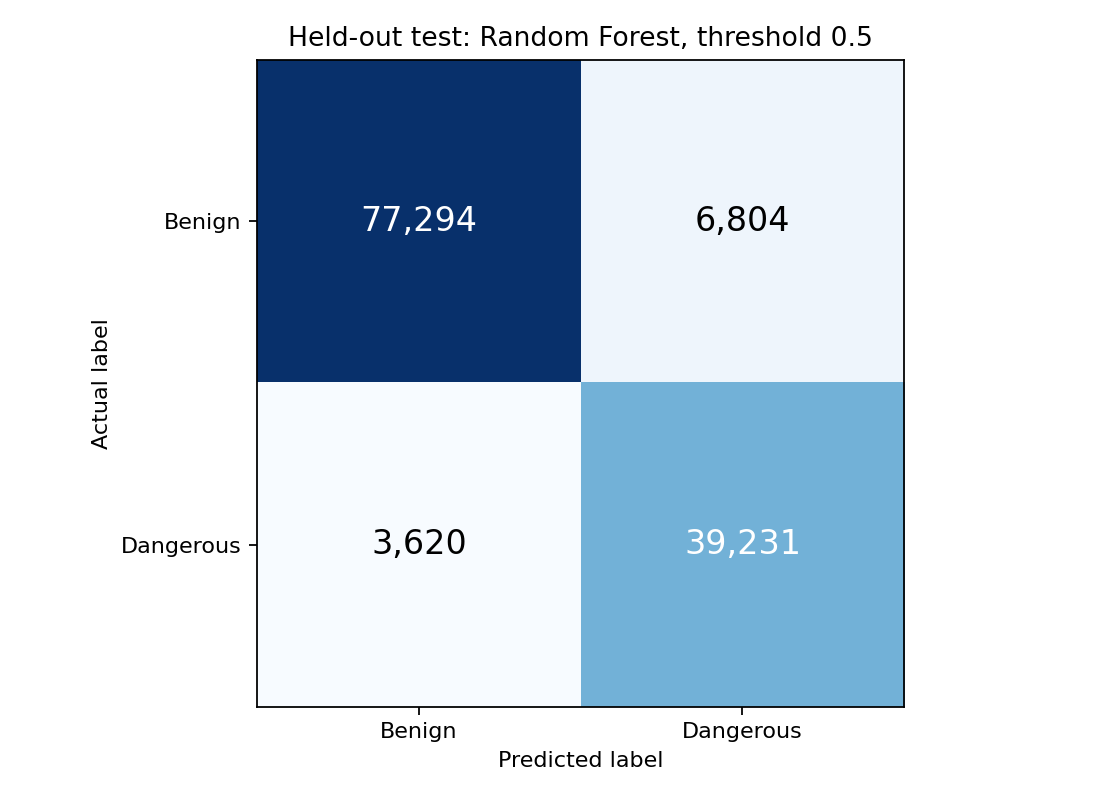

,class_or_average,precision,recall,f1-score,support
0,benign,0.955261,0.919094,0.936829,84098.000000
1,potentially_dangerous,0.852199,0.915521,0.882726,42851.000000
2,accuracy,0.917888,0.917888,0.917888,0.917888
3,macro avg,0.903730,0.917308,0.909778,126949.000000
4,weighted avg,0.920473,0.917888,0.918567,126949.000000


,source_type,rows,correct,correct_rate,missed_dangerous,false_alarms,dangerous_recall,benign_false_alarm_rate
0,benign,84098,77294,0.919094,0,6804,NaN,0.080906
1,phishing,18757,15635,0.833555,3122,0,0.833555,NaN
2,malware,3643,3274,0.898710,369,0,0.898710,NaN
3,defacement,20451,20322,0.993692,129,0,0.993692,NaN


In [2]:
display(Image(filename=str(ROOT / "reports/figures/test_confusion_matrix.png")))
display(pd.read_csv(ROOT / "reports/evaluation/classification_report.csv"))
display(pd.read_csv(ROOT / "reports/evaluation/test_subgroups.csv"))


Không mở URL trong error analysis. Các ví dụ được chọn theo URL ID, bao phủ FP/FN và nhãn gốc. Bảng bên dưới chỉ hiện signals; đọc URL dưới dạng escaped text trong report để tránh biến URL thành liên kết.


In [3]:
examples = pd.read_csv(ROOT / "reports/evaluation/error_examples.csv")
display(examples.drop(columns=["url"]))
print("Report: reports/evaluation/stage-7-evaluation-report.md")
print("Reload test probabilities within 1e-12:", summary["reload_all_test_probabilities_match_tolerance"])
print("Raw URL equivalence checks:", summary["raw_url_equivalence_checked"])
print("Offline new URL checks:", summary["offline_new_urls_checked"])


Report: reports/evaluation/stage-7-evaluation-report.md
Reload test probabilities within 1e-12: True
Raw URL equivalence checks: 120
Offline new URL checks: 5


,url_id,type,target,probability,prediction,outcome,url_length,has_scheme,uses_https,has_ip_host,has_suspicious_term,query_parameter_count,parse_ok
0,000bbbb7e5efdd24d9a8f7e31b17fa3d0747aa57921950...,benign,0,0.577919,1,FP,30,0,0,0,0,0,1
1,000cad0b59f8e6bae85a333a168aab516115414be3bc23...,benign,0,0.824697,1,FP,24,0,0,0,0,0,1
2,001004d36c6c17656ee3523c1c5d1a714f4d8d1cf1a125...,benign,0,0.804012,1,FP,22,0,0,0,0,0,1
3,001bb0015d09c781feee474b6c2f038f52d10eb58acd9c...,benign,0,0.524098,1,FP,54,0,0,0,0,1,1
4,001c697b03ee16a364e1182212309f54ede1eeee56b3a7...,benign,0,0.703988,1,FP,27,0,0,0,0,0,1
5,000ab657235d8e2c841d1ef8ab08138e8afec8c0fe974e...,phishing,1,0.391704,0,FN,34,0,0,0,0,0,1
6,001eaa3956d90c6976fc9bac0c5e40cc0fc59d7358e62f...,phishing,1,0.435625,0,FN,40,0,0,0,0,0,1
7,002cc935c581530f83afc9666732c36aacaaf73acc7d7e...,phishing,1,0.475711,0,FN,62,0,0,0,0,0,1
8,00581d239acd507bf5d5820980ec178b897c25e0e831d0...,phishing,1,0.115640,0,FN,55,0,0,0,0,2,1
9,005c55c208aedb1947ac655a991e22d7dc069d69adbf34...,phishing,1,0.315889,0,FN,36,0,0,0,0,0,1


Saved pipeline: offline parser → 36 features đúng thứ tự → Random Forest → threshold 0.5. Không dùng clustering scaler. Xác suất chưa calibrated; prediction benign không đảm bảo an toàn.


In [4]:
pipeline = load_pipeline()
results = pipeline.predict_urls(["https://example.com/", "http://192.0.2.1:8080/login?verify=1", "https://[broken"])
display(pd.DataFrame(results))


,predicted_class,label,dangerous_probability,threshold,probability_calibrated,parse_ok,parse_issues
0,1,Potentially dangerous,0.955067,0.5,False,True,[]
1,1,Potentially dangerous,0.956848,0.5,False,True,[]
2,1,Potentially dangerous,0.774188,0.5,False,False,[invalid_structure]


## Hạn chế

Source/format bias, nhãn chưa kiểm chứng độc lập, lexical-only model và thiếu temporal evaluation giới hạn kết luận. Test đã mở cho final evaluation; không retune bằng kết quả này. Stage 8 sẽ dùng các bằng chứng để viết báo cáo và đóng gói.
